# Simulasi Sistem Kendali PID pada Sistem Massa-Pegas-Peredam

Notebook ini mensimulasikan sistem mekanik sederhana dengan persamaan gerak:
$$m\ddot{x} + b\dot{x} + kx = F(t)$$

Dengan gaya masukan $F(t)$ diatur oleh pengendali PID.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameter Sistem Mekanik
m = 1.0   # Massa (kg)
b = 2.0   # Koefisien redaman (N.s/m)
k = 10.0  # Konstanta pegas (N/m)
setpoint = 1.0  # Target posisi (meter)

In [2]:
def simulasi_pid(Kp, Ki, Kd, t_akhir=10.0, dt=0.01):
    t = np.arange(0, t_akhir, dt)
    n = len(t)
    
    x = np.zeros(n)
    v = np.zeros(n)
    F_log = np.zeros(n)
    
    integral_error = 0.0
    prev_error = setpoint - x[0]
    
    for i in range(1, n):
        error = setpoint - x[i-1]
        
        P = Kp * error
        integral_error += error * dt
        I = Ki * integral_error
        derivative_error = (error - prev_error) / dt
        D = Kd * derivative_error
        
        F = P + I + D
        F_log[i] = F
        
        a = (F - b * v[i-1] - k * x[i-1]) / m
        v[i] = v[i-1] + a * dt
        x[i] = x[i-1] + v[i] * dt
        
        prev_error = error
        
    return t, x, F_log

def simulasi_open_loop(F_konstan=10.0, t_akhir=10.0, dt=0.01):
    t = np.arange(0, t_akhir, dt)
    x, v = np.zeros(len(t)), np.zeros(len(t))
    for i in range(1, len(t)):
        a = (F_konstan - b * v[i-1] - k * x[i-1]) / m
        v[i] = v[i-1] + a * dt
        x[i] = x[i-1] + v[i] * dt
    return t, x

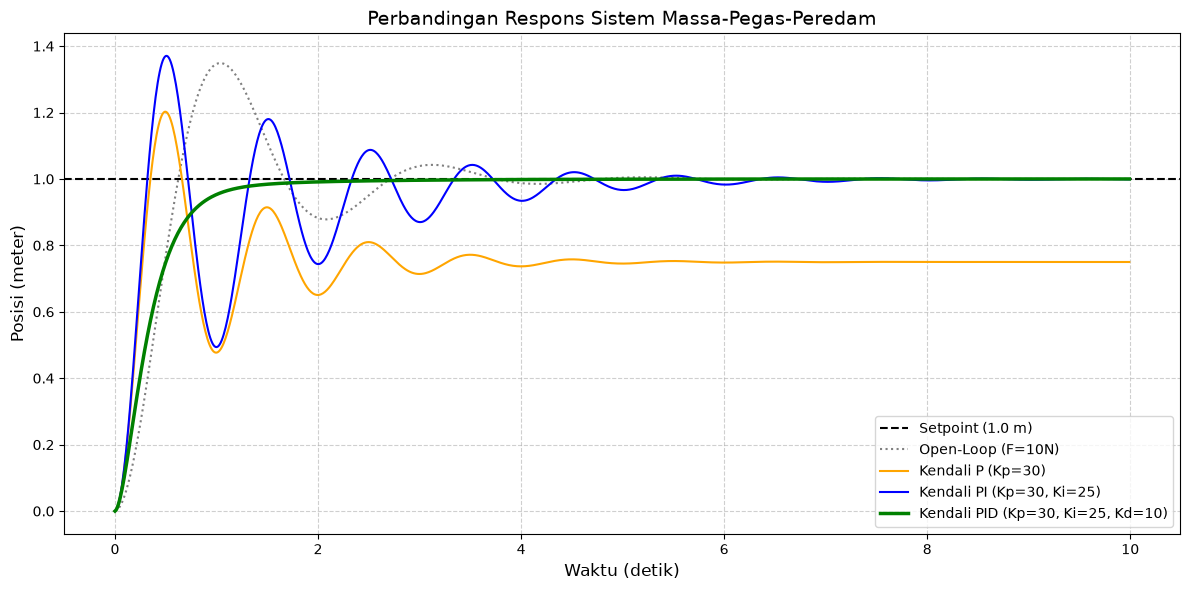

In [3]:
t, x_open = simulasi_open_loop(F_konstan=10.0)
_, x_p, _ = simulasi_pid(Kp=30.0, Ki=0.0, Kd=0.0)
_, x_pi, _ = simulasi_pid(Kp=30.0, Ki=25.0, Kd=0.0)
_, x_pid, F_pid = simulasi_pid(Kp=30.0, Ki=25.0, Kd=10.0)

plt.figure(figsize=(12, 6))
plt.axhline(setpoint, color='black', linestyle='--', linewidth=1.5, label='Setpoint (1.0 m)')
plt.plot(t, x_open, label='Open-Loop (F=10N)', linestyle=':', color='gray')
plt.plot(t, x_p, label='Kendali P (Kp=30)', color='orange')
plt.plot(t, x_pi, label='Kendali PI (Kp=30, Ki=25)', color='blue')
plt.plot(t, x_pid, label='Kendali PID (Kp=30, Ki=25, Kd=10)', color='green', linewidth=2.5)

plt.title('Perbandingan Respons Sistem Massa-Pegas-Peredam', fontsize=14)
plt.xlabel('Waktu (detik)', fontsize=12)
plt.ylabel('Posisi (meter)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
from ipywidgets import interact, FloatSlider

def plot_interaktif(Kp=30.0, Ki=25.0, Kd=10.0):
    t, x, F = simulasi_pid(Kp, Ki, Kd)
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    
    # Subplot 1: Posisi
    ax1.axhline(setpoint, color='r', linestyle='--', label='Setpoint (1.0 m)')
    ax1.plot(t, x, color='green', linewidth=2, label='Posisi Aktual')
    ax1.set_ylabel('Posisi (m)')
    ax1.set_title(f'Simulasi Tuning PID (Kp={Kp}, Ki={Ki}, Kd={Kd})')
    ax1.set_ylim(-0.2, 1.8)
    ax1.grid(True)
    ax1.legend()
    
    # Subplot 2: Gaya Aktuator
    ax2.plot(t, F, color='purple', label='Gaya Kendali / Aktuator (N)')
    ax2.set_xlabel('Waktu (detik)')
    ax2.set_ylabel('Gaya (Newton)')
    ax2.grid(True)
    ax2.legend()
    
    plt.tight_layout()
    plt.show()

interact(plot_interaktif, 
         Kp=FloatSlider(min=0, max=100, step=1, value=30),
         Ki=FloatSlider(min=0, max=100, step=1, value=25),
         Kd=FloatSlider(min=0, max=50, step=0.5, value=10))

interactive(children=(FloatSlider(value=30.0, description='Kp', step=1.0), FloatSlider(value=25.0, description…

<function __main__.plot_interaktif(Kp=30.0, Ki=25.0, Kd=10.0)>